# Step 1 — An image is just a grid of numbers

Before any machine learning, you need to be comfortable with one idea:
**a photo, to a computer, is a big table of numbers.** Nothing else.

Run each cell with **Shift + Enter**.

If something breaks, that's fine — tell me what the error says.

In [33]:
# numpy = the library for working with grids of numbers
# matplotlib = the library for drawing pictures
import numpy as np
import matplotlib.pyplot as plt

# Load our images. mmap_mode='r' means "don't load all 800 MB into memory,
# just read bits of the file when I ask for them".
images = np.load('../data/processed/X_train.npy', mmap_mode='r')
labels = np.load('../data/processed/y_train.npy')

print('how many images do we have?', len(images))
print('how many labels do we have?', len(labels))


how many images do we have? 5321
how many labels do we have? 5321


You should see **5321** twice.

That's our training set: 5,321 photos, and 5,321 labels saying whether each
one shows damage.

Now let's pull out a single photo and look at what it actually *is*.

In [34]:
# Python counts from 0, so image number 0 is the first one.
photo = images[0]

print('shape :', photo.shape)
print('dtype :', photo.dtype)
print('smallest number in it:', photo.min())
print('biggest number in it :', photo.max())

shape : (224, 224, 3)
dtype : uint8
smallest number in it: 9
biggest number in it : 255


Read that output carefully, because it tells you everything:

- **shape `(224, 224, 3)`** — 224 rows, 224 columns, and 3 numbers per
  position. Those 3 are how much **R**ed, **G**reen and **B**lue.
- **dtype `uint8`** — "unsigned 8-bit integer", i.e. a whole number from
  0 to 255. That's the normal range for an image: 0 = none of that colour,
  255 = as much as possible.

So this photo is **224 × 224 × 3 = 150,528 numbers**. That's it. That's the
whole picture.

Let's prove it by looking at a few of them.

In [35]:
# One single pixel: row 100, column 100
print('the pixel at row 100, column 100 is:', photo[100, 100])
print('   its red value  :', photo[100, 100, 0])
print('   its green value:', photo[100, 100, 1])
print('   its blue value :', photo[100, 100, 2])

# A tiny 4x4 patch, red channel only, so you can see the actual grid
print()
print('a 4x4 patch of red values:')
print(photo[100:104, 100:104, 0])

the pixel at row 100, column 100 is: [198 133  93]
   its red value  : 198
   its green value: 133
   its blue value : 93

a 4x4 patch of red values:
[[198 209 211 205]
 [199 204 202 196]
 [203 204 201 197]
 [195 201 204 204]]


Those numbers **are** the image. Now let's draw them.

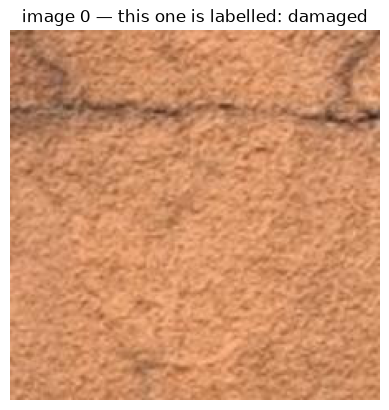

In [36]:
names = ['undamaged', 'damaged']

plt.imshow(photo)
plt.title(f'image 0 — this one is labelled: {names[labels[0]]}')
plt.axis('off')
plt.show()

---

## Your turn

Play with the cell below. Things to try:

1. Change `n` to a different number (anything from 0 to 5320) and re-run.
2. Find an image where you **disagree** with the label. They exist.
3. Try `n = 99999` and see what error you get. Errors are information.

Tell me what you find.

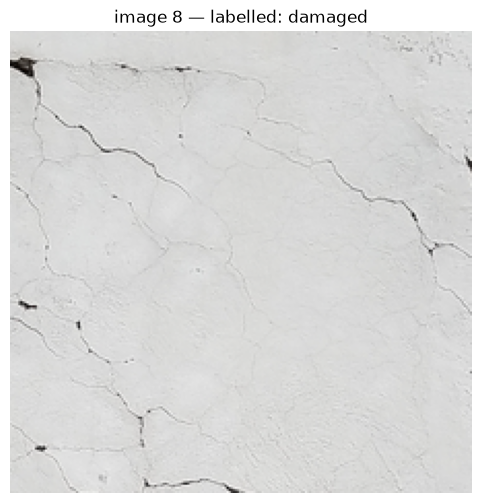

In [37]:
n =  8     # <-- change this number and press Shift+Enter

plt.figure(figsize=(6, 6))
plt.imshow(images[n])
plt.title(f'image {n} — labelled: {names[labels[n]]}')
plt.axis('off')
plt.show()

---
# Step 2 — Teaching a computer to guess

We have 5,321 photos and 5,321 labels. The goal: a program that looks at a
photo it has never seen and says *damaged* or *undamaged*.

Before building anything clever, we need to know **what score is worth
nothing**. Otherwise we can't tell a good model from a useless one.


## The dumbest possible model

Here is a 'model' that does no learning at all. It ignores the photo
completely and always shouts the same answer.

If 54% of images are undamaged, then always saying *undamaged* is right 54%
of the time. **Any real model must beat that**, or it has learned nothing.


In [38]:
import numpy as np

y_val = np.load('../data/processed/y_val.npy')

always_undamaged = (y_val == 0).mean()
always_damaged   = (y_val == 1).mean()

print(f'always saying "undamaged": {always_undamaged:.1%} correct')
print(f'always saying "damaged"  : {always_damaged:.1%} correct')
print()
print(f'So our baseline to beat is {max(always_undamaged, always_damaged):.1%}')


always saying "undamaged": 53.4% correct
always saying "damaged"  : 46.6% correct

So our baseline to beat is 53.4%


## How do you feed a photo to a model?

Most classic models don't understand grids. They want one long list of
numbers per example - a *row*.

So we **flatten**: take the 224 x 224 x 3 grid and lay all its numbers out
in a single line.


In [39]:
images = np.load('../data/processed/X_train.npy', mmap_mode='r')

one = np.asarray(images[0])
print('before flattening:', one.shape)

flat = one.reshape(-1)        # -1 means 'work out the length yourself'
print('after flattening :', flat.shape)
print()
print('224 * 224 * 3 =', 224*224*3)
print('first 10 numbers:', flat[:10])


before flattening: (224, 224, 3)
after flattening : (150528,)

224 * 224 * 3 = 150528
first 10 numbers: [158 113  80 160 115  82 159 113  80 150]


## Now notice something uncomfortable

Each photo is **150,528 numbers**. We have **5,321 photos**.

The model has roughly **28 times more knobs to tune than examples to learn
from**.

Think about what that lets it do. Instead of learning *what damage looks
like*, it can simply memorise all 5,321 photos.

### Predict before you run

The next cell trains a real model (logistic regression) on 800 photos, then
scores it two ways:

- on the **same 800 photos it learned from**
- on **592 photos it has never seen**

Write down your guesses for both numbers before running it. Remember the
baseline is about 53%.


## Wait - check the data first

Before training on `images[:800]`, ask a question a lot of people skip:
**is taking the first 800 rows actually a fair sample?**

Run this.


In [40]:
y_train = np.load('../data/processed/y_train.npy')

print('the first 30 labels :', y_train[:30])
print('the last  30 labels :', y_train[-30:])
print()
first800 = y_train[:800]
print(f'in the first 800: {(first800==1).sum()} damaged, {(first800==0).sum()} undamaged')


the first 30 labels : [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
the last  30 labels : [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

in the first 800: 800 damaged, 0 undamaged


### That is a trap, and it is a real one

The file is **sorted by class**. The first 2,451 images are all damaged,
the last 2,870 all undamaged.

So `images[:800]` is 800 damaged photos and nothing else. A model trained
on that can score 100% by saying 'damaged' every single time - it has never
seen the other class exist.

> This exact bug was sitting in our real `repro/baselines.py` until this
> notebook cell crashed and exposed it. The SVM there had been training on
> 90.8% damaged data instead of 46%. A crash is a gift; a silent skew is not.

The fix: take a **random** sample, keeping the class ratio. That is called
a *stratified* sample.


In [43]:
rng = np.random.default_rng(0)

n = 1000   # how many training photos to use (keep it small - this is slow)

# pick n rows at random, keeping the 46/54 damaged/undamaged ratio
pick = []
for cls in (0, 1):
    pool = np.flatnonzero(y_train == cls)
    k = round(n * len(pool) / len(y_train))
    pick.append(rng.choice(pool, k, replace=False))
pick = np.sort(np.concatenate(pick))

print(f'sample: {(y_train[pick]==1).sum()} damaged, {(y_train[pick]==0).sum()} undamaged')


sample: 461 damaged, 539 undamaged


In [45]:
from sklearn.linear_model import LogisticRegression

val_images = np.load('../data/processed/X_val.npy', mmap_mode='r')

# Flatten the sampled photos into rows, and scale 0-255 down to 0-1.
X = np.asarray(images[pick], dtype=np.float32).reshape(len(pick), -1) / 255.0
y = y_train[pick]
X_val = np.asarray(val_images, dtype=np.float32).reshape(len(y_val), -1) / 255.0

print(f'training on {X.shape[0]} photos, each with {X.shape[1]} numbers...')
model = LogisticRegression(max_iter=1000)
model.fit(X, y)

print()
print(f'score on the photos it LEARNED from : {model.score(X, y):.1%}')
print(f'score on photos it has NEVER seen   : {model.score(X_val, y_val):.1%}')
print(f'baseline (always guess undamaged)   : {always_undamaged:.1%}')


training on 1000 photos, each with 150528 numbers...

score on the photos it LEARNED from : 100.0%
score on photos it has NEVER seen   : 51.0%
baseline (always guess undamaged)   : 53.4%


## What just happened

If your output looks like ours, the model scored **near 100%** on the photos
it trained on, and **barely above the baseline** on new ones.

That is the most important failure mode in machine learning, and it has a
name: **overfitting**.

The model did not learn what damage looks like. It memorised 800 specific
photos. Ask it about one it memorised and it is perfect. Ask it about a new
one and it is guessing.

> **A high training score means nothing on its own.** It is not a result,
> it is a symptom. Always compare against unseen data, and always compare
> against the do-nothing baseline.


## Your turn

1. Change `n` to 200 and re-run. Does the training score go **up** or
   **down**? Why would fewer photos be *easier* to memorise?
2. Try `n = 2000` (slower, maybe a minute). Does the unseen score improve?
3. The paper got 54.7% on unseen data with this model. Did you?

Tell me your numbers.


---
# Step 3 - Why pixels fail, and what fixes it

Step 2 ended badly: ~99% on photos the model memorised, ~54% on new ones,
against a 53.4% baseline. Basically useless.

So *why*? Here is the problem, in one picture.


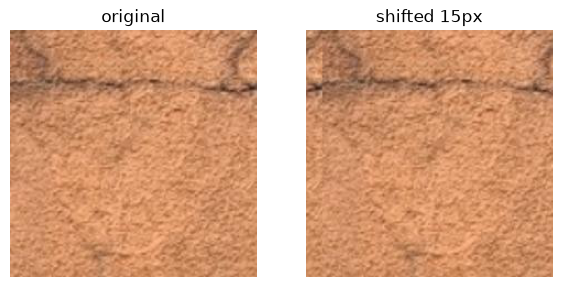

how many of the 150,528 numbers are identical? 2.1%


In [46]:
import matplotlib.pyplot as plt

# Take one damaged photo and shift it 15 pixels to the right.
orig = np.asarray(images[0])
shifted = np.roll(orig, 15, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(orig);    ax[0].set_title('original');       ax[0].axis('off')
ax[1].imshow(shifted); ax[1].set_title('shifted 15px');   ax[1].axis('off')
plt.show()

# To a human these are the same crack. To the pixel model?
a = orig.reshape(-1).astype(float)
b = shifted.reshape(-1).astype(float)
print('how many of the 150,528 numbers are identical?',
      f'{(a == b).mean():.1%}')


### That is the whole problem

You and I see the same wall with the same crack. The model sees two almost
entirely different lists of numbers.

Position 54,321 in the list does not mean 'crack'. It means 'the blue value
of the pixel at row 120, column 181'. Move the camera slightly and every
number changes.

A model built on raw pixels has to memorise *exact arrangements of light*.
That is why it memorises and cannot generalise.


## The fix: stop using pixels

Instead of feeding raw pixels, feed **descriptions**.

Imagine a function that looks at a photo and reports things like *'there is
a long thin dark line here'*, *'this surface is rough'*, *'there is a
repeating grid pattern'*. Those stay true when the camera moves 15 pixels.

We do not have to write that function. **Someone else already trained one.**

A network called InceptionV3 was trained on 14 million photos of everyday
objects. To tell a cat from a bus it had to learn edges, textures, shapes.
We throw away its final 'is it a cat' layer and keep the description it
produces: **2,048 numbers per photo**.

That is called **transfer learning** - borrowing what a network learned on
one job to do a different job.

We already ran this over every photo and saved the results, so loading them
is instant.


In [50]:
feat_train = np.load('../results/features/incv3_train.npy')
feat_val   = np.load('../results/features/incv3_val.npy')

print('raw pixels per photo      :', 224*224*3)
print('InceptionV3 numbers       :', feat_train.shape[1])
print()
print('training set shape:', feat_train.shape)
print('first 8 numbers for photo 0:', feat_train[0][:8].round(3))


raw pixels per photo      : 150528
InceptionV3 numbers       : 2048

training set shape: (5321, 2048)
first 8 numbers for photo 0: [0.622 0.072 0.    0.505 0.4   0.131 1.137 0.304]


### Predict before you run

Next we train **exactly the same logistic regression as Step 2**. Same
model, same settings. The only difference is what we feed it: 2,048
descriptions instead of 150,528 pixels.

Step 2 gave us ~54% on unseen photos. **What do you think we get now?**

Guess a number before running.


In [56]:
from sklearn.linear_model import LogisticRegression

model2 = LogisticRegression(max_iter=1000)
model2.fit(feat_train, y_train)

train2 = model2.score(feat_train, y_train)
val2   = model2.score(feat_val, y_val)

print('             on photos it learned from   on photos never seen')
print(f'raw pixels            ~99%                       ~54%')
print(f'InceptionV3          {train2:>5.1%}                     {val2:>5.1%}')
print()
print(f'baseline (guess the common class): {always_undamaged:.1%}')


             on photos it learned from   on photos never seen
raw pixels            ~99%                       ~54%
InceptionV3          98.2%                     77.5%

baseline (guess the common class): 53.4%


## That jump is the whole project

Same model. Same data. Same labels. The *only* change was describing each
photo in 2,048 meaningful numbers instead of 150,528 raw pixels.

Unseen accuracy goes from *barely above chance* to genuinely useful.

> This is the paper's central claim, and you just reproduced it yourself in
> about ten lines.

Note it also uses **73x less data per photo**, so it trains in seconds
instead of minutes.


## Your turn

1. In the cell above, train on only the first 500 rows:
   `model2.fit(feat_train[:500], y_train[:500])` - careful, remember what
   you learned about sorted data! Use a stratified sample instead.
2. How few photos can you train on and still beat 70% on unseen data?
3. Compare that with how many raw-pixel photos you needed to beat 55%.

Tell me what you find.


---
# Step 4 - Your experiment: does more data help?

We trained on 5,321 photos because the 2018 paper used that many and we
were reproducing it. But Berkeley now publishes **11,811**.

So: would twice the data give a better model? Do not guess - measure.

**Write your prediction down now.** Mine is below, hidden in plain sight so
you can check afterwards whether I was right:

> I predict under 2 points of improvement, probably about 1.


## The rule that makes this a fair test

Change **one** thing. Train on more photos, but score on the **same 592
validation photos** as before. If you also change what you score against,
the comparison means nothing.

`pool_is_val.npy` marks which pool rows are already in your validation set,
so you can keep them out of training.


In [53]:
import numpy as np

feat_pool = np.load('../results/features/incv3_pool.npy')
y_pool    = np.load('../data/processed/y_pool.npy')
is_val    = np.load('../data/processed/pool_is_val.npy')

feat_val = np.load('../results/features/incv3_val.npy')
y_val    = np.load('../data/processed/y_val.npy')

trainable = np.flatnonzero(~is_val)
print(f'pool              : {len(y_pool)}')
print(f'in validation set : {is_val.sum()}')
print(f'usable for training: {len(trainable)}   (we used 5321)')


pool              : 11811
in validation set : 592
usable for training: 11219   (we used 5321)


## Run the sweep

Train the same logistic regression at several dataset sizes and record the
score on the fixed validation set each time.

Note the stratified sampling - you know why that matters now.


In [54]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)

def stratified(rows, labels, n):
    """Pick n of `rows` at random, keeping the class ratio."""
    out = []
    for cls in (0, 1):
        pool = rows[labels[rows] == cls]
        k = round(n * len(pool) / len(rows))
        out.append(rng.choice(pool, min(k, len(pool)), replace=False))
    return np.concatenate(out)

sizes = [1000, 2500, 5321, 8000, 11219]
scores = []

for n in sizes:
    idx = stratified(trainable, y_pool, n)
    m = LogisticRegression(max_iter=1000)
    m.fit(feat_pool[idx], y_pool[idx])
    s = m.score(feat_val, y_val)
    scores.append(s)
    print(f'  trained on {len(idx):>6} photos  ->  validation {s:.1%}')


  trained on   1000 photos  ->  validation 73.1%
  trained on   2500 photos  ->  validation 74.3%
  trained on   5321 photos  ->  validation 75.8%
  trained on   8000 photos  ->  validation 78.5%
  trained on  11219 photos  ->  validation 79.1%


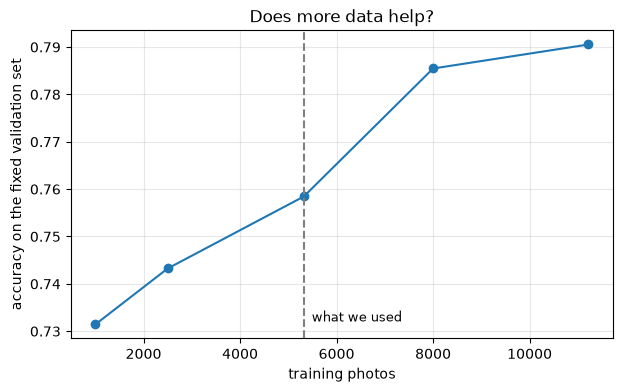

going from 5,321 to 11,219 photos changed accuracy by +3.2%


In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(sizes, scores, 'o-')
plt.axvline(5321, ls='--', c='grey')
plt.text(5321, min(scores), '  what we used', va='bottom', fontsize=9)
plt.xlabel('training photos')
plt.ylabel('accuracy on the fixed validation set')
plt.title('Does more data help?')
plt.grid(alpha=.3)
plt.show()

gain = scores[-1] - scores[2]        # 11219 vs 5321
print(f'going from 5,321 to 11,219 photos changed accuracy by {gain:+.1%}')


## Now interpret it

Answer these in your own words - they are exactly what a reviewer would
ask:

1. Was my prediction right?
2. Is the curve still climbing at 11,219, or has it flattened?
3. If it has flattened: more data is not the bottleneck, so **what is?**
   You have two candidates from earlier - the quality of the 2,048
   descriptions, and the mislabelled images in the dataset.
4. Would you keep the bigger training set in the final project? Note that
   using it means you are no longer matching the paper's setup.

> Either answer is a real result. 'More data does not help, and here is the
> evidence' is a stronger statement than a number that went up a bit.


---
# Step 5 - How does it fail?

We have a model at about 83%. Knowing *that* number is nearly useless on
its own. The question that matters is **which 17% does it get wrong, and
why?**

Let's load the real production model and look at its mistakes.


In [57]:
import torch, torch.nn as nn

# the trained production model: one linear layer, 2048 inputs -> 2 outputs
head = nn.Linear(2048, 2)
head.load_state_dict(torch.load('../results/head_full_299.pt',
                                map_location='cpu'))
head.eval()

feat_test = np.load('../results/features/incv3_test_299.npy')
y_test    = np.load('../data/processed/y_test.npy')
X_test    = np.load('../data/processed/X_test.npy', mmap_mode='r')

with torch.no_grad():
    logits = head(torch.from_numpy(feat_test))
    probs  = torch.softmax(logits, dim=1).numpy()
pred = probs.argmax(1)

print(f'test images : {len(y_test)}')
print(f'accuracy    : {(pred == y_test).mean():.1%}')


test images : 1460
accuracy    : 82.9%


## The confusion matrix

Accuracy squashes two very different mistakes into one number. Separate
them:

- **false positive** - model cried damage at an intact building. Annoying.
- **false negative** - model missed real damage. **Dangerous.**

For a tool that triages buildings after an earthquake, those are not
equally bad.


In [58]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, pred)
print('                 predicted')
print('               undam    dam')
print(f'true undam    {cm[0,0]:>6} {cm[0,1]:>6}   <- {cm[0,1]} false alarms')
print(f'true dam      {cm[1,0]:>6} {cm[1,1]:>6}   <- {cm[1,0]} MISSED damage')
print()
print(classification_report(y_test, pred,
                           target_names=['undamaged','damaged'],
                           digits=3))


                 predicted
               undam    dam
true undam       601    114   <- 114 false alarms
true dam         136    609   <- 136 MISSED damage

              precision    recall  f1-score   support

   undamaged      0.815     0.841     0.828       715
     damaged      0.842     0.817     0.830       745

    accuracy                          0.829      1460
   macro avg      0.829     0.829     0.829      1460
weighted avg      0.829     0.829     0.829      1460



### Reading that report

- **recall** for *damaged* = of all genuinely damaged buildings, what
  fraction did we catch? **This is the safety number.**
- **precision** for *damaged* = when we shout damage, how often are we
  right? This is the wasted-inspection number.

The paper's recall for damage was 74.9%. Compare yours.


## Now look at the actual mistakes

Sort the errors by how **confident** the model was. A confident mistake is
far more informative than a 51% coin-flip - it tells you the model has
learned something actively wrong.


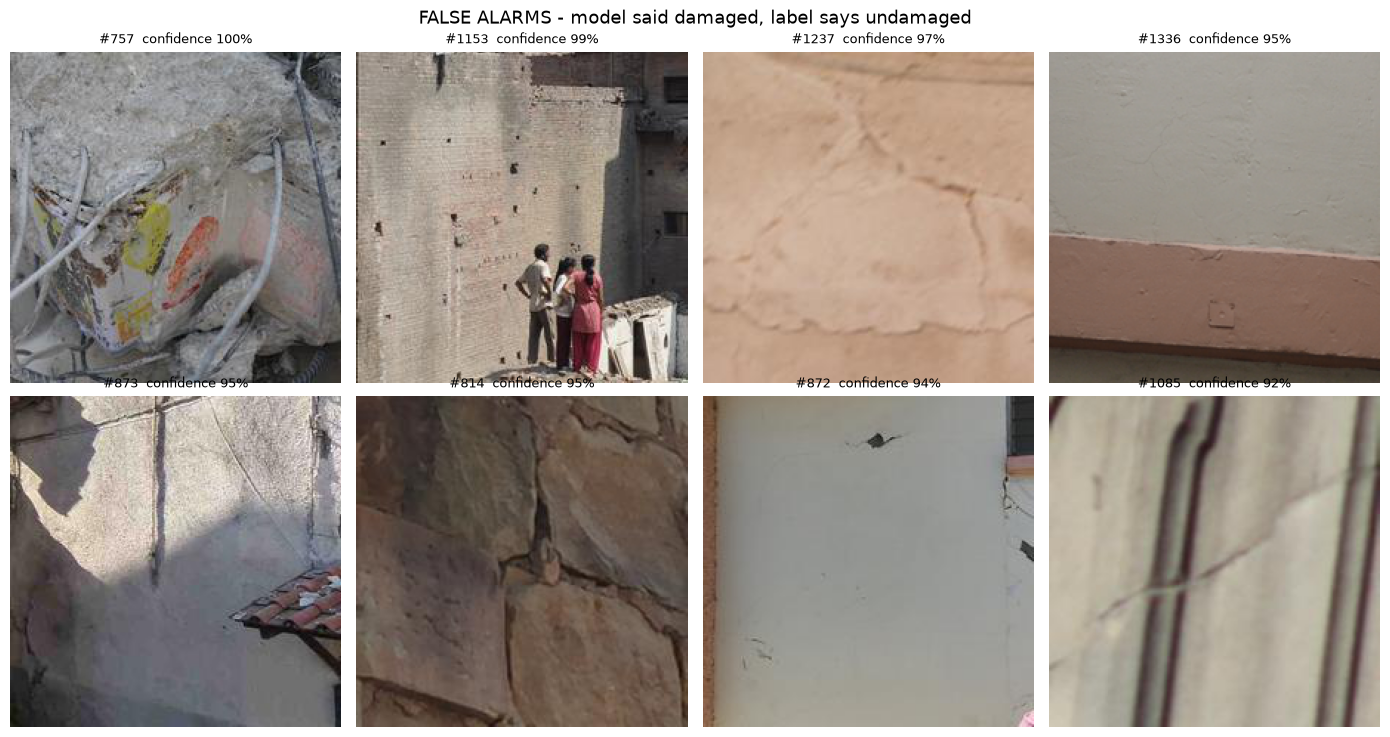

In [59]:
import matplotlib.pyplot as plt
names = ['undamaged', 'damaged']

def show_errors(kind, n=8):
    if kind == 'fp':   # said damaged, was undamaged
        rows = np.flatnonzero((y_test == 0) & (pred == 1))
        rows = rows[np.argsort(-probs[rows, 1])]
        title = 'FALSE ALARMS - model said damaged, label says undamaged'
    else:              # said undamaged, was damaged
        rows = np.flatnonzero((y_test == 1) & (pred == 0))
        rows = rows[np.argsort(-probs[rows, 0])]
        title = 'MISSED DAMAGE - model said undamaged, label says damaged'
    rows = rows[:n]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax in np.ravel(axes): ax.axis('off')
    for ax, i in zip(np.ravel(axes), rows):
        ax.imshow(np.asarray(X_test[i]))
        ax.set_title(f'#{i}  confidence {probs[i].max():.0%}', fontsize=9)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(); plt.show()

show_errors('fp')


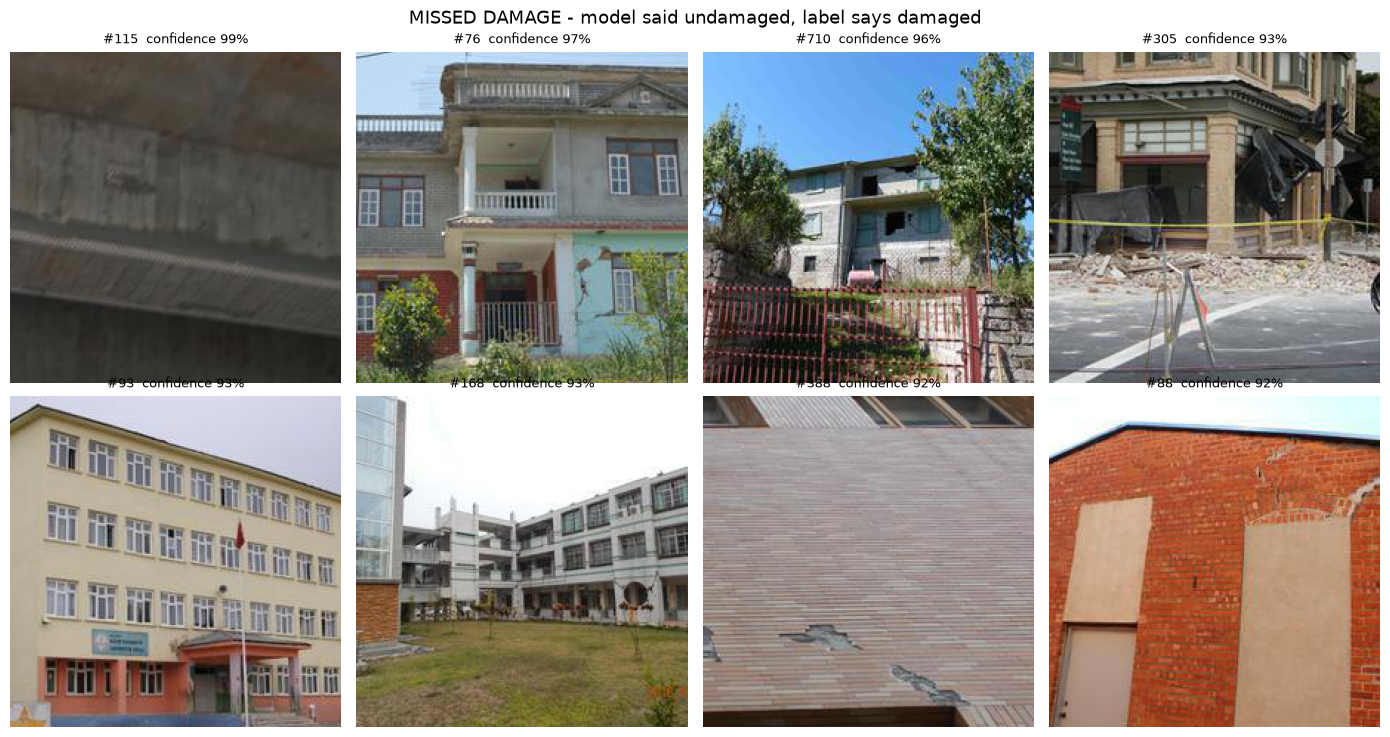

In [60]:
show_errors('fn')


## Your turn - be the error analyst

This is the part that makes a project look like research rather than a
tutorial. Study both galleries and answer:

1. Among the **false alarms**, how many are actually the model's fault?
   Look carefully - some of those 'undamaged' images visibly contain
   damage. If the label is wrong, the model was right.
2. Among the **missed damage**, is there something the images have in
   common? Compare how close-up they are against the false alarms.
3. Finish this sentence from the evidence: *"the model has really learned
   to detect ______, which is not the same thing as damage."*

Write your answers down. These are exactly the questions a reviewer asks,
and 'I looked at 16 failures and here is the pattern' is a far stronger
answer than a number.


---
# Step 6 - Is the model short on data, or short on ideas?

When a model plateaus you have two very different problems, and the fix
for one makes the other worse:

| | symptom | fix |
|---|---|---|
| **high variance** (overfitting) | great on training data, poor on new data | more data, simpler model |
| **high bias** (underfitting) | mediocre on *both* | bigger model, better features |

You cannot tell which you have from a single accuracy number. You need a
**learning curve**: accuracy against training-set size, tracking training
and validation together.

This diagnostic decides what you do next, so getting it right matters.


In [61]:
from sklearn.linear_model import LogisticRegression

feat_pool = np.load('../results/features/incv3_pool.npy')
y_pool    = np.load('../data/processed/y_pool.npy')
is_val    = np.load('../data/processed/pool_is_val.npy')
feat_val  = np.load('../results/features/incv3_val.npy')
y_val     = np.load('../data/processed/y_val.npy')
trainable = np.flatnonzero(~is_val)

rng = np.random.default_rng(0)

def stratified(rows, labels, n):
    out = []
    for cls in (0, 1):
        pool = rows[labels[rows] == cls]
        k = round(n * len(pool) / len(rows))
        out.append(rng.choice(pool, min(k, len(pool)), replace=False))
    return np.concatenate(out)

sizes = [200, 500, 1000, 2500, 5000, 8000, 11219]
tr_acc, va_acc = [], []

for n in sizes:
    idx = stratified(trainable, y_pool, n)
    m = LogisticRegression(max_iter=1000)
    m.fit(feat_pool[idx], y_pool[idx])
    t = m.score(feat_pool[idx], y_pool[idx])   # only rows it saw
    v = m.score(feat_val, y_val)
    tr_acc.append(t); va_acc.append(v)
    print(f'  {len(idx):>6} photos   train {t:.1%}   val {v:.1%}   gap {t-v:+.1%}')


     200 photos   train 100.0%   val 70.1%   gap +29.9%
     500 photos   train 100.0%   val 74.2%   gap +25.8%
    1000 photos   train 100.0%   val 72.6%   gap +27.4%
    2500 photos   train 99.9%   val 73.3%   gap +26.6%
    5000 photos   train 98.2%   val 76.0%   gap +22.2%
    8000 photos   train 93.0%   val 78.2%   gap +14.8%
   11219 photos   train 90.5%   val 78.9%   gap +11.6%


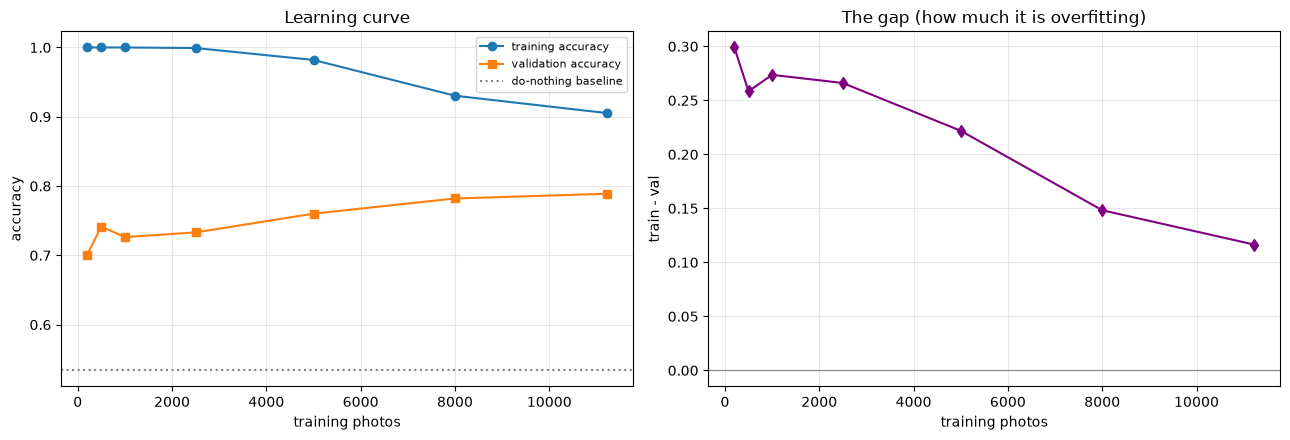

In [62]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))

a.plot(sizes, tr_acc, 'o-', label='training accuracy')
a.plot(sizes, va_acc, 's-', label='validation accuracy')
a.axhline(0.534, ls=':', c='grey', label='do-nothing baseline')
a.set_xlabel('training photos'); a.set_ylabel('accuracy')
a.set_title('Learning curve'); a.legend(fontsize=8); a.grid(alpha=.3)

b.plot(sizes, np.array(tr_acc) - np.array(va_acc), 'd-', color='purple')
b.axhline(0, c='grey', lw=.8)
b.set_xlabel('training photos'); b.set_ylabel('train - val')
b.set_title('The gap (how much it is overfitting)'); b.grid(alpha=.3)

plt.tight_layout(); plt.show()


## Read your own curve

Work through these in order:

1. At 200 photos, how big is the gap? Training near 100% with validation
   far below it is the classic **variance** signature.
2. What happens to the gap as photos are added? If it shrinks, extra data
   is doing its job.
3. Look at the **validation** line on the right-hand side. Still rising, or
   flat? If flat, more data will not rescue you.
4. So which is it at 11,219 photos - bias or variance? Careful: a shrinking
   gap *and* a flat validation line at once means neither label quite fits.

> The paper looked at its version of this plot and wrote "clearly a bias
> issue", then added model capacity in response. Having seen your own
> curve: do you agree with them?

There is no trick answer here. Write what you actually see, with reasons.


---
# Step 7 - Where is the ceiling?

More data has stopped helping. So what is holding the model at ~83%?

Two suspects:

1. **The features.** Those 2,048 numbers come from a network trained to
   tell cats from buses. ImageNet holds 1,190 structural images out of 14.2
   million - about 0.008%. Maybe they simply do not describe cracks well.
2. **The labels.** You have already seen images where the dataset is wrong.
   **No model can beat the quality of its ground truth.**

Suspect 2 is measurable, and as far as we can tell nobody has published the
number for this dataset. Let's find it.


## Experiment: how noisy are the labels?

Run the next cell. It shows you 20 random test images **without their
labels**. Judge each one yourself: damaged or not.

Be honest, and do not peek at the answer cell first - a biased measurement
is worth nothing.


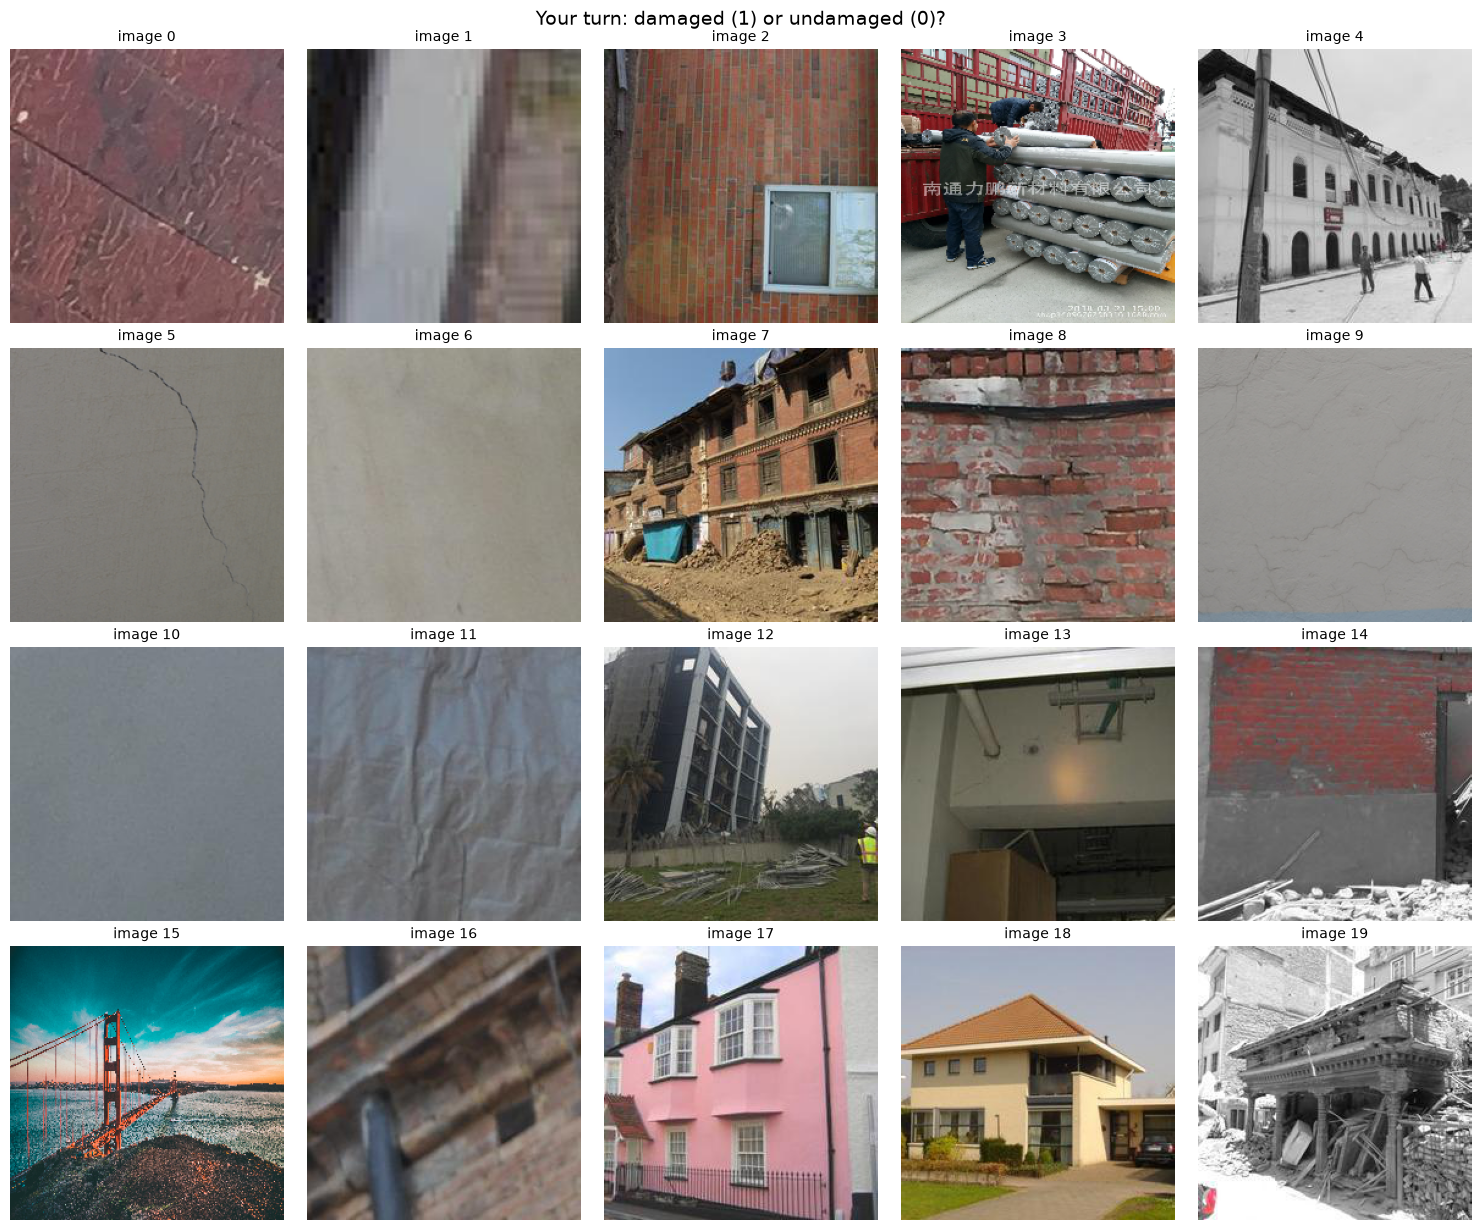

In [63]:
rng2 = np.random.default_rng(7)      # change the seed for a fresh set
sample = rng2.choice(len(y_test), 20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(15, 12.5))
for ax in np.ravel(axes): ax.axis('off')
for k, (ax, i) in enumerate(zip(np.ravel(axes), sample)):
    ax.imshow(np.asarray(X_test[i]))
    ax.set_title(f'image {k}', fontsize=10)
fig.suptitle('Your turn: damaged (1) or undamaged (0)?', fontsize=14)
fig.tight_layout(); plt.show()


In [65]:
# Type your 20 answers here, in order: 1 = damaged, 0 = undamaged
my_labels = [
    # 0, 1, 2, 3, 4,
    # 5, 6, 7, 8, 9,
    # 10, 11, 12, 13, 14,
    # 15, 16, 17, 18, 19,
]

if len(my_labels) != 20:
    print('fill in all 20 first')
else:
    mine    = np.array(my_labels)
    dataset = y_test[sample]
    agree   = (mine == dataset).mean()
    print(f'you and the dataset agree on {agree:.0%} of images')
    print(f'you disagree on {(mine != dataset).sum()} of 20')
    print()
    for k, i in enumerate(sample):
        if mine[k] != dataset[k]:
            print(f'  image {k} (test row {i}): you said {names[mine[k]]}, dataset says {names[dataset[k]]}')


fill in all 20 first


## What your number means

Suppose you disagree with the dataset on 10% of images. Some of those are
you being wrong - but some are the dataset being wrong, and you saw
concrete examples of that back in Step 5.

If roughly 5-10% of labels are unreliable, then **a perfect model would
still score about 90-95%**, because the remaining answers are simply wrong.
Our 83% is closer to that ceiling than to 100%.

> Re-run with a few different seeds to get a steadier estimate. One sample
> of 20 is very noisy - this is the same lesson as running three seeds for
> the learning curve.

### Why this is worth putting in your write-up

It reframes the whole result. "Our model gets 83%" invites *why so low?*
"Our model gets 83% against an estimated label-noise ceiling of ~90%" is a
much stronger claim - and it is one the original authors gestured at but
never measured.

---

## That's the walkthrough

You have been through the whole project: what an image is, why raw pixels
fail, why transfer learning works, whether more data helps, how the model
fails, and where the ceiling is.

If you want to rebuild it yourself from scratch, `docs/COURSE.md` is the
same path as a set of exercises with checkpoints instead of answers.
